# 02. AR on the daily anomaly

Verdict: The AR on the daily anomaly beats the naive baselines but stays far behind RTE, mostly in winter. MAE test: AR(8) + normal 1.69 GW vs RTE raw 1.16 GW (+46.3 %).

Setup: Cutoff D 12:00, forecast the 24 h of D+1, test 1 Jul 2025 to 30 Jun 2026.
Daily mean in GW (course milestones m2/m3), not comparable with the hourly MW of other notebooks.

## 1. Setup

Daily mean consumption in GW. At the cutoff the last full day is D-1, so D+1 is a 2-step-ahead forecast.

Train is 1 Jan 2023 to 30 Jun 2025 (after the energy crisis, the mean dropped in 2022-2023 per the KPSS in 00_eda). Test is 1 Jul 2025 to 30 Jun 2026.

In [1]:
import sys
sys.path.insert(0, "../src")

from datetime import date, timedelta

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import pacf
from statsmodels.tsa.ar_model import AutoReg
from watt_forecast.data_preprocessing import DAILY_KEYS, load_daily, save_predictions
from watt_forecast.models.ar import seasonal_normal, ar_forecast
from watt_forecast.metrics import compute_metrics, scorecard_daily

TRAIN_START, TRAIN_END = date(2023, 1, 1), date(2025, 6, 30)
TEST_START, TEST_END = date(2025, 7, 1), date(2026, 6, 30)

pl.Config.set_tbl_rows(20)
plt.rcParams["figure.figsize"] = (12, 4)

In [2]:
daily = load_daily().filter(pl.col("date").is_between(TRAIN_START, TEST_END))
train_mask = (daily["date"] <= TRAIN_END).to_numpy()

assert (daily["date"].diff().drop_nulls() == timedelta(days=1)).all(), "the daily series should have no gap"
assert daily.height == train_mask.sum() + 365, "the test period should have 365 days"
assert daily["target"].null_count() == 0, "the daily consumption should have no nulls"
print(daily.height, "days |", train_mask.sum(), "train days |", (~train_mask).sum(), "test days")
daily.head()

1277 days | 912 train days | 365 test days


date,target,temperature_c,rte_gw
date,f64,f64,f64
2023-01-01,43.104667,13.435,41.473458
2023-01-02,49.727875,10.79,50.076542
2023-01-03,55.974583,8.210417,56.560917
2023-01-04,56.937833,10.409167,57.270333
2023-01-05,55.405375,11.355833,55.799958


## 2. Model

As in TP02 (Part D), we split consumption into a normal (yearly cycle + day of week) and an anomaly, then fit an AR(p) on the anomaly.

### The normal and the anomaly

seasonal_normal fits, on train days only, 2 Fourier pairs (period 365.25 days) plus one level per weekday. Then anomaly = consumption - normal.

In [3]:
y_train = daily["target"].to_numpy()[train_mask]
daily = daily.with_columns(seasonal_normal(daily, TRAIN_END))
daily = daily.with_columns((pl.col("target") - pl.col("normal_gw")).alias("anomaly_gw"))

anom = daily["anomaly_gw"].to_numpy()
anom_train = anom[train_mask]
assert abs(anom_train.mean()) < 1e-6, "least squares with day intercepts gives a train anomaly of mean 0"
print(f"std of the consumption {y_train.std():.2f} GW, std of the train anomaly {anom_train.std():.2f} GW")

std of the consumption 9.43 GW, std of the train anomaly 3.80 GW


### Choosing p

TP02 rule: largest lag in 1..10 with |PACF| > 0.1. The AIC grid (A.4) gives the same p.

In [4]:
pacf_anom = pacf(anom_train, nlags=10)
p = max(k for k in range(1, 11) if abs(pacf_anom[k]) > 0.1)

print("PACF lags 1 to 10:", np.round(pacf_anom[1:], 3))
print("PACF rule: p =", p)

PACF lags 1 to 10: [ 0.877 -0.223  0.018 -0.032 -0.029  0.002 -0.029 -0.138  0.01   0.038]
PACF rule: p = 8


### The AR model

In [5]:
res = AutoReg(anom_train, lags=p).fit()
params = res.params

assert len(params) == p + 1, "one constant plus p coefficients"
print("params [c, phi_1, ..., phi_p]:", np.round(params, 3))
print(f"sigma: {np.sqrt(res.sigma2):.2f} GW")

params [c, phi_1, ..., phi_p]: [ 0.025  1.093 -0.254  0.027 -0.002 -0.031 -0.008  0.138 -0.144]
sigma: 1.66 GW


\(\hat\phi_1 \approx 1.09\) and \(\hat\phi_2 \approx -0.25\) carry the persistence, lags 3 to 6 are near zero. \(\hat\phi_7 \approx 0.14\) and \(\hat\phi_8 \approx -0.14\) almost cancel, probably a weekday effect the dummies miss. Noise is about 1.7 GW vs 3.8 GW for the anomaly.

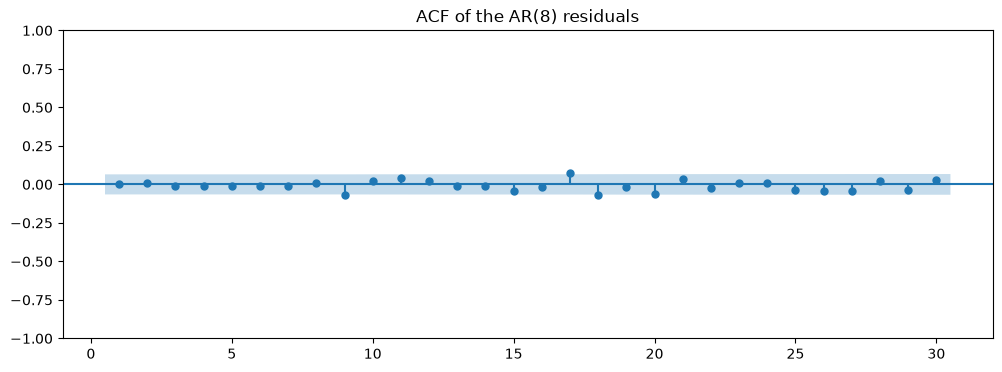

In [6]:
resid = res.resid
resid_dates = daily["date"].filter(pl.Series(train_mask))[p:]
assert len(resid) == len(resid_dates), "one residual per train day after the first p days"

plot_acf(resid, lags=30, zero=False, title=f"ACF of the AR({p}) residuals")
plt.show()

Residual ACF stays inside the band (lags 9, 17, 18 just touch it). Close enough to white noise.

### Day-ahead forecasts on the test year

For each test day T we forecast the anomaly 2 steps ahead from T-2 and add back the normal of T (calendar only, so known in advance):

forecast of T = normal of T + anomaly of T forecast from T-2

In [7]:
dates = daily["date"].to_list()
normal = daily["normal_gw"].to_numpy()
test_pos = np.where(~train_mask)[0]

# history = the p anomalies of days T-p-1 to T-2
ar_pred = [ar_forecast(params, anom[i - p - 1:i - 1], 2)[-1] + normal[i] for i in test_pos]

i0 = test_pos[0]
first_history = dates[i0 - p - 1:i0 - 1]
assert dates[i0] == TEST_START, "the first forecast should be for the first test day"
assert max(first_history) == TEST_START - timedelta(days=2), "the first forecast should use no data after T-2"
assert len(first_history) == p, "the AR needs p past anomalies"

Compared: seasonal naive (T-7), normal only (anomaly = 0), AR(p) + normal, and the daily mean of RTE raw.

In [8]:
daily = daily.with_columns(pl.col("target").shift(7).alias("naive_7d_gw"))
test = (
    daily.filter(pl.col("date").is_between(TEST_START, TEST_END))
    .with_columns(pl.Series("ar_gw", ar_pred))
)

forecasts = {
    "Seasonal naive (T-7)": "naive_7d_gw",
    "Normal only": "normal_gw",
    f"AR({p}) + normal": "ar_gw",
    "RTE raw": "rte_gw",
}
assert test.height == 365, "one forecast per test day"
assert test.select(forecasts.values()).null_count().sum_horizontal().item() == 0, "no missing forecast"

In [9]:
# Test forecasts of this notebook (with the daily RTE reference), read by 06_comparison
save_predictions(test, forecasts, "02_ar", keys=DAILY_KEYS)

## 3. Results vs benchmark

In [10]:
scorecard_daily(test, forecasts)

forecast,MAE,bias,vs_reference_(%)
str,f64,f64,f64
"""Seasonal naive (T-7)""",3.29,-0.05,185.1
"""Normal only""",2.66,-0.6,129.9
"""AR(8) + normal""",1.69,-0.17,46.3
"""RTE raw""",1.16,-1.09,0.0


The normal alone already beats the seasonal naive (2.66 vs 3.29 GW) and the AR cuts that by more than a third (1.69 GW). RTE raw is still well ahead at 1.16 GW.

## 4. Where it fails

A cold week: 5 to 11 January 2026.

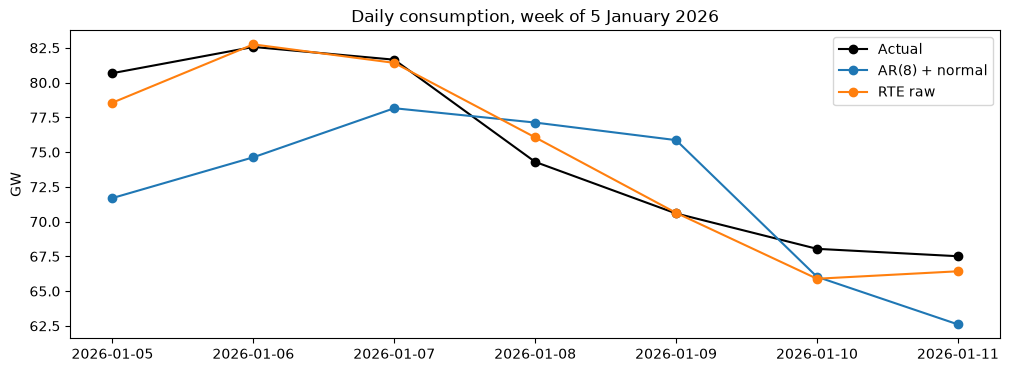

In [11]:
week = test.filter(pl.col("date").is_between(date(2026, 1, 5), date(2026, 1, 11)))

plt.plot(week["date"], week["target"], color="k", marker="o", label="Actual")
plt.plot(week["date"], week["ar_gw"], marker="o", label=f"AR({p}) + normal")
plt.plot(week["date"], week["rte_gw"], marker="o", label="RTE raw")
plt.title("Daily consumption, week of 5 January 2026")
plt.ylabel("GW")
plt.legend()
plt.show()

The AR is about two days late. It misses the cold Monday by 9 GW (71.7 vs 80.7 GW) and is still high on Friday after the load has dropped (75.9 vs 70.6 GW). RTE raw stays within about 2 GW all week.

## 5. Conclusion

- Normal + anomaly works: the anomaly behaves like an AR and both the PACF rule and the AIC give p = 8. AR(8) + normal reaches 1.69 GW.
- RTE raw is still better (1.16 GW). The gap is in winter (1.4 to 2.6 times RTE raw from November to March), since the AR reacts to cold spells two days late and holidays give the biggest residuals.
- Kept for next step: the normal + anomaly idea. For m3 we try SARIMA, then SARIMAX with temperature and holidays (observed D+1 temperature only gives an upper bound).

## Appendix

### A.1 ACF and PACF of the raw daily consumption

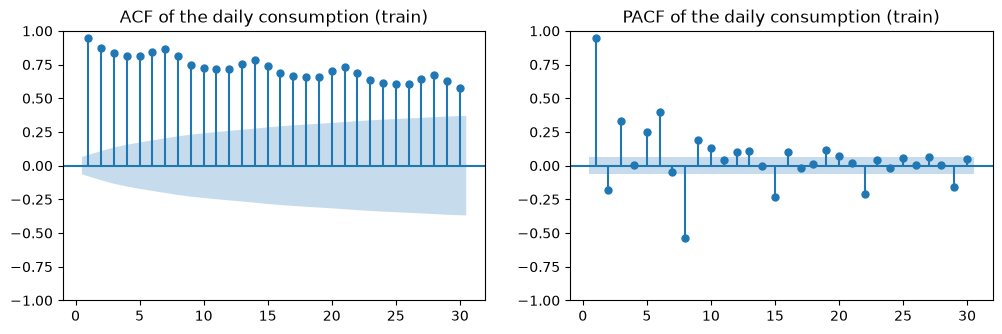

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(y_train, lags=30, zero=False, ax=ax[0], title="ACF of the daily consumption (train)")
plot_pacf(y_train, lags=30, zero=False, ax=ax[1], title="PACF of the daily consumption (train)")
plt.show()

Slow decay (about 0.6 at lag 30) from the yearly cycle, plus bumps at 7, 14, 21, 28 from the week. An AR on this would need a lot of lags, so we remove the seasonality first.

### A.2 The normal and the anomaly over one year

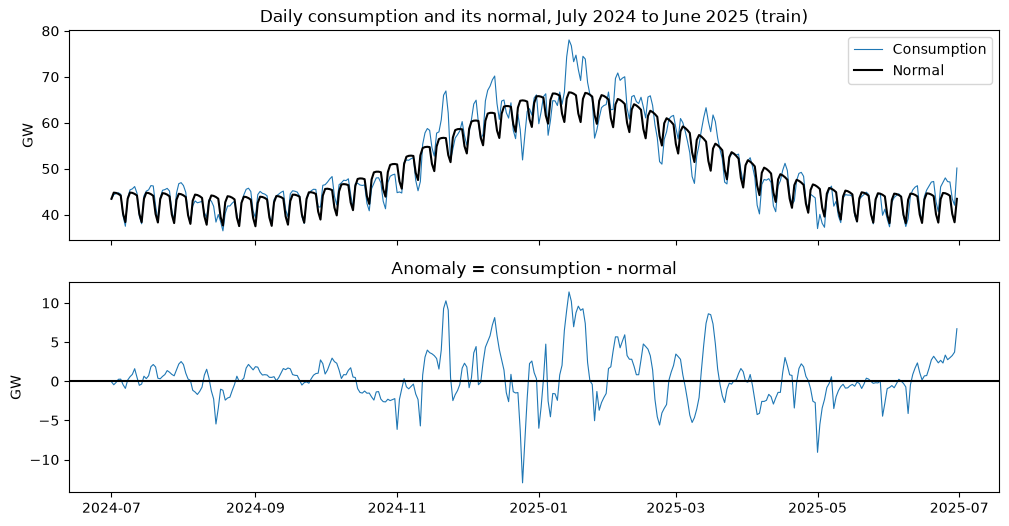

In [13]:
year = daily.filter(pl.col("date").is_between(date(2024, 7, 1), TRAIN_END))

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(year["date"], year["target"], lw=0.8, label="Consumption")
ax[0].plot(year["date"], year["normal_gw"], color="k", label="Normal")
ax[0].set_title("Daily consumption and its normal, July 2024 to June 2025 (train)")
ax[0].set_ylabel("GW")
ax[0].legend()
ax[1].plot(year["date"], year["anomaly_gw"], lw=0.8)
ax[1].axhline(0, color="k")
ax[1].set_title("Anomaly = consumption - normal")
ax[1].set_ylabel("GW")
plt.show()

The anomaly is much smaller than the load (std 3.8 vs 9.4 GW), calm in summer, ±10 GW in winter. The big negative spikes are holidays, which the normal doesn't know about.

### A.3 ACF and PACF of the anomaly

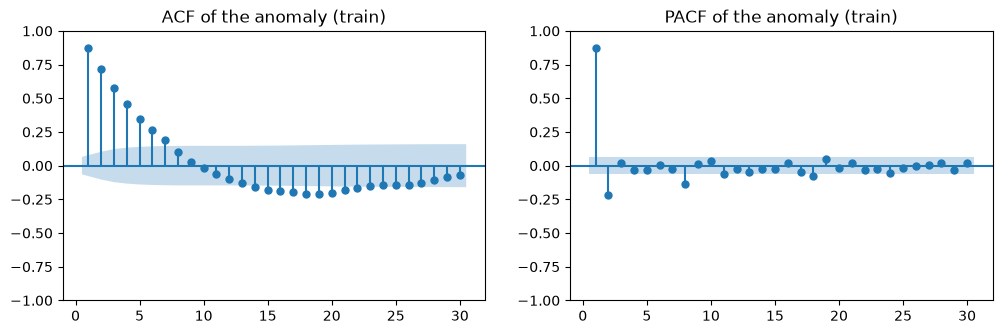

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(anom_train, lags=30, zero=False, ax=ax[0], title="ACF of the anomaly (train)")
plot_pacf(anom_train, lags=30, zero=False, ax=ax[1], title="PACF of the anomaly (train)")
plt.show()

Now it looks like an AR: the ACF decays (0.88, 0.72, 0.58, ...), the PACF has a big lag 1, a negative lag 2 and a small bar at 8. The weekly peaks are gone.

### A.4 AIC grid

AutoReg for p = 1 to 10, all with hold_back=10 so the AICs are comparable.

In [15]:
aic = pl.DataFrame({
    "p": range(1, 11),
    "AIC": [AutoReg(anom_train, lags=k, hold_back=10).fit().aic for k in range(1, 11)],
})
p_aic = aic.sort("AIC")["p"][0]

print("PACF rule: p =", p, "| AIC: p =", p_aic)
aic.with_columns(pl.col("AIC").round(1), (pl.col("AIC") - pl.col("AIC").min()).round(1).alias("AIC_-_min"))

PACF rule: p = 8 | AIC: p = 8


p,AIC,AIC_-_min
i64,f64,f64
1,3563.3,64.8
2,3508.4,9.8
3,3510.3,11.8
4,3511.6,13.0
5,3513.0,14.5
6,3515.0,16.4
7,3516.6,18.1
8,3498.5,0.0
9,3500.5,2.0


Both methods give p = 8. Most of the gain is at p = 2 (AIC drops by 55 from p = 1), lags 3 to 7 add nothing, lag 8 takes off about 10 more.

We do not fit a pure MA: the ACF decays slowly instead of cutting off, and an MA(q) forecast 2 steps ahead returns to the mean as soon as q < 2. MA terms are used in the SARIMA of `03`.

### A.5 Top 5 residuals

In [16]:
top_resid = (
    pl.DataFrame({"date": resid_dates, "residual_gw": resid})
    .with_columns(pl.col("date").dt.strftime("%A").alias("weekday"))
    .sort(pl.col("residual_gw").abs(), descending=True)
    .head(5)
)
top_resid.join(daily.select("date", "temperature_c"), on="date").with_columns(pl.col("residual_gw", "temperature_c").round(2))

date,residual_gw,weekday,temperature_c
date,f64,str,f64
2023-12-25,-8.26,"""Monday""",9.71
2024-01-19,7.11,"""Friday""",-1.0
2024-05-02,8.05,"""Thursday""",11.77
2024-11-24,-7.0,"""Sunday""",14.47
2025-01-05,-7.6,"""Sunday""",9.87


No surprises. 25 Dec 2023 is a holiday, 2 May 2024 is the day after 1 May (the AR expected the low to persist), 5 Jan 2025 is the end of the Christmas break, and 19 Jan 2024 is a fast cold snap (-1 °C). Calendar and temperature are what's missing.

### A.6 All metrics on the test year

In [17]:
results = pl.DataFrame(
    [{"forecast": name, **compute_metrics(test, col, actual_col="target")} for name, col in forecasts.items()]
)
results.select("forecast", "MAE", "bias", "RMSE", "MAPE").with_columns(pl.col("MAE", "bias", "RMSE", "MAPE").round(2))

forecast,MAE,bias,RMSE,MAPE
str,f64,f64,f64,f64
"""Seasonal naive (T-7)""",3.29,-0.05,4.88,6.12
"""Normal only""",2.66,-0.6,3.79,4.91
"""AR(8) + normal""",1.69,-0.17,2.44,3.2
"""RTE raw""",1.16,-1.09,1.34,2.35


Daily means in GW, not comparable with the hourly MAEs of 01_baseline. RTE raw underestimates by 1.09 GW, as in 01_baseline. The normal alone is 0.6 GW low, so the test year was a bit above 2023-2025.

### A.7 Winter 2025-2026

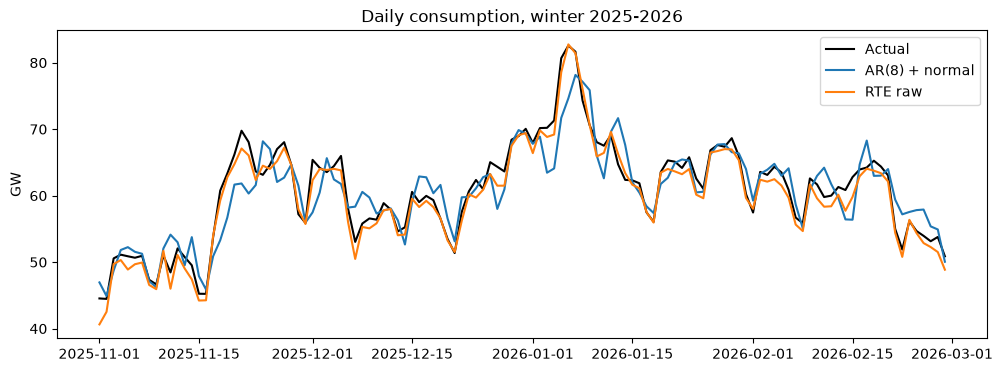

In [18]:
winter = test.filter(pl.col("date").is_between(date(2025, 11, 1), date(2026, 2, 28)))

plt.plot(winter["date"], winter["target"], color="k", label="Actual")
plt.plot(winter["date"], winter["ar_gw"], label=f"AR({p}) + normal")
plt.plot(winter["date"], winter["rte_gw"], label="RTE raw")
plt.title("Daily consumption, winter 2025-2026")
plt.ylabel("GW")
plt.legend()
plt.show()

Close most of the time but about two days late, as expected with no weather input (see mid-November and early January). RTE raw follows the peaks, slightly below.

### A.8 MAE by month

In [19]:
mae_by_month = (
    test.group_by(pl.col("date").dt.strftime("%Y-%m").alias("month"))
    .agg(
        (pl.col("ar_gw") - pl.col("target")).abs().mean().alias(f"AR({p})_+_normal"),
        (pl.col("rte_gw") - pl.col("target")).abs().mean().alias("RTE_raw"),
        pl.col("temperature_c").mean().alias("mean_temp_(°C)"),
    )
    .sort("month")
)
mae_by_month.with_columns(pl.exclude("month").round(2))

month,AR(8)_+_normal,RTE_raw,mean_temp_(°C)
str,f64,f64,f64
"""2025-07""",1.03,0.92,21.44
"""2025-08""",0.97,0.94,21.78
"""2025-09""",0.66,0.94,16.46
"""2025-10""",0.77,1.0,13.14
"""2025-11""",2.88,1.27,9.05
"""2025-12""",2.52,1.07,7.04
"""2026-01""",2.7,1.02,5.25
"""2026-02""",2.25,1.3,8.89
"""2026-03""",1.99,1.4,9.61


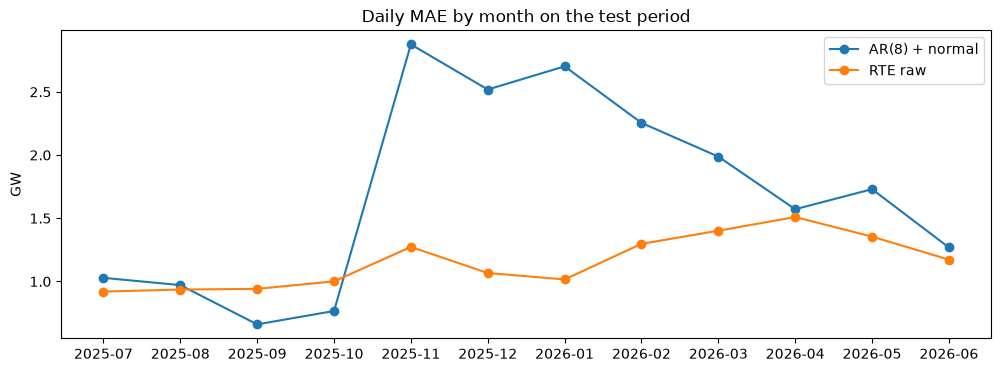

In [20]:
for col in [f"AR({p})_+_normal", "RTE_raw"]:
    plt.plot(mae_by_month["month"], mae_by_month[col], marker="o", label=col.replace("_", " "))
plt.title("Daily MAE by month on the test period")
plt.ylabel("GW")
plt.legend()
plt.show()

July to October the AR is as good as RTE raw, even better in September and October. From November to March it is 1.4 to 2.6 times worse (worst in November and January), when load is driven by temperature.